# 07 · Parameters

Part 3 of the study plan (`docs/study_plan.md`): realistic bounds for the model's parameters and the poll input of the
empirical mode, from the polls. Nothing here runs the model. Blocks: **poll noise ρ<sub>s</sub> and temperature θ**,
then prior spread ρ<sub>π</sub>, tolerance (paired scenarios), real-world ranges for the synthetic setup, and the
empirical poll input.

The ABM's synthetic poll (docs/model.md, *Generated polls*): s̃<sub>i</sub> ∝ (δ<sub>i</sub> + ε)<sup>1/θ</sup>, then
s ~ Dirichlet(ρ<sub>s</sub> · s̃). Current Saltelli bounds: θ ∈ [0.3, 3], ρ<sub>s</sub> ∈ [10, 200]
(`analysis/synthetic/parameter_space.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, ideology, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
BOUNDS = {"theta": (0.3, 3.0), "rho_s": (10.0, 200.0), "rho_pi": (5.0, 200.0)}

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
b = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")].copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
slot_vals = b[b["slot"].notna()].groupby(["election", "poll_id", "slot"]).agg(
    value=("value", "sum"), days_before=("days_before", "first"), phase=("phase", "first")).reset_index()
core = results[results["share"] >= 2.0].rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]]

## 1 · Poll noise ρ<sub>s</sub>

Since Var(s<sub>i</sub>) = s<sub>i</sub>(1 − s<sub>i</sub>)/(ρ<sub>s</sub> + 1), ρ<sub>s</sub> = *n*<sub>eff</sub> − 1, with
*n*<sub>eff</sub> = mean *p*(100 − *p*) / mean squared deviation (shares in points). Three readings:

- **single poll**: the scatter of one poll around the poll average (notebook 05, section 5): what one poll adds as noise;
- **weekly average**: a voter reading the mean of a week's polls; if the polls of a week were independent, its
  *n*<sub>eff</sub> would be the single-poll one times the polls per week (herding makes them less independent, so this is
  an upper bound);
- **total**: the poll average a week before the vote against the result, core candidates: noise, pollsters' common
  bias and real late movement together (a lower bound).

In [2]:
noise = pd.read_csv(TABLES / "noise_effective_sample_size.csv")
single = noise.pivot(index="election", columns="period", values="n_eff")
per_week = (slot_vals.drop_duplicates("poll_id").assign(w=lambda d: d["days_before"] <= 28)
            .query("w").groupby("election")["poll_id"].nunique() / 4)

avg7 = pd.concat([average.by_candidate(g, "value", np.array([7])).assign(election=e)
                  for e, g in slot_vals.groupby("election")], ignore_index=True).dropna(subset=["mean"])
tot = avg7.merge(core)
tot["sq"] = (tot["result"] - tot["mean"]) ** 2
tot["pq"] = tot["mean"] * (100 - tot["mean"])
total = tot.groupby("election").apply(lambda g: g["pq"].mean() / g["sq"].mean(), include_groups=False)

rho = pd.DataFrame({
    "single poll, campaign": single["last 12 months"] - 1,
    "single poll, last two weeks": single["last two weeks"] - 1,
    "polls per week, last 4 weeks": per_week,
    "weekly average, last 4 weeks (upper bound)": single["last two weeks"] * per_week - 1,
    "total, 1 week before vs result (lower bound)": total - 1,
})
rho.round(0).to_csv(TABLES / "parameters_rho_s.csv")
print(f"Current bounds for ρ_s: {BOUNDS['rho_s']}")
rho.round(0)

Current bounds for ρ_s: (10.0, 200.0)


,"single poll, campaign","single poll, last two weeks","polls per week, last 4 weeks","weekly average, last 4 weeks (upper bound)","total, 1 week before vs result (lower bound)"
election,,,,,
2002,876.0,934.0,6.0,5377.0,180.0
2007,491.0,1003.0,8.0,8030.0,322.0
2012,843.0,1072.0,6.0,6708.0,456.0
2017,752.0,1813.0,10.0,17683.0,728.0
2022,780.0,890.0,15.0,13369.0,101.0


## 2 · Temperature θ

**(A) Candidate by candidate.** For the core candidates (≥ 2% in the result), log(polled share) against log(result
share), with the polled share the mean of the last two weeks: slope = 1/θ. Over each election, and over each poll of
the last two weeks (its distribution). θ < 1: polls exaggerate the gaps; θ > 1: they flatten them.

**(B) Shape only.** Shares sorted, log share against log rank, in the last-two-weeks poll average and in the result:
θ = slope<sub>result</sub> / slope<sub>polls</sub>. It compares how steeply support falls with rank, whoever holds each
rank, so it is not affected by candidates swapping places.

Both treat the result as the true support. The result also contains the late switching the model is meant to produce,
so θ measured here mixes poll distortion with that switching.

In [3]:
last = slot_vals[slot_vals["phase"] == timeline.PHASES[2]]
lp = last.groupby(["election", "slot"])["value"].mean().rename("polled").reset_index().merge(core)

def slope_a(d):
    return np.polyfit(np.log(d["result"]), np.log(d["polled"]), 1)[0]

def slope_b(shares):
    s = np.sort(np.asarray(shares, float))[::-1]
    return np.polyfit(np.log(np.arange(1, len(s) + 1)), np.log(s), 1)[0]

rng = np.random.default_rng(7)
theta = []
for e in ELECTIONS:
    d = lp[lp["election"] == e]
    per_poll = []
    for pid, g in last[last["election"] == e].groupby("poll_id"):
        g = g.merge(core)
        if len(g) >= 4:
            per_poll.append(1 / np.polyfit(np.log(g["result"]), np.log(g["value"]), 1)[0])
    # bootstrap over the polls of the last two weeks
    pids = last[last["election"] == e]["poll_id"].unique()
    boots_a, boots_b = [], []
    for _ in range(1000):
        sel = last[last["poll_id"].isin(rng.choice(pids, len(pids)))]
        m = sel.groupby("slot")["value"].mean().rename("polled").reset_index().merge(core[core["election"] == e])
        boots_a.append(1 / slope_a(m))
        boots_b.append(slope_b(core[core["election"] == e]["result"]) / slope_b(m["polled"]))
    theta.append(dict(election=e, candidates=len(d),
                      theta_A=1 / slope_a(d), theta_A_low=np.percentile(boots_a, 2.5), theta_A_high=np.percentile(boots_a, 97.5),
                      theta_A_single_polls_median=np.median(per_poll),
                      theta_A_single_polls_p10=np.percentile(per_poll, 10), theta_A_single_polls_p90=np.percentile(per_poll, 90),
                      theta_B=slope_b(core[core["election"] == e]["result"]) / slope_b(d["polled"]),
                      theta_B_low=np.percentile(boots_b, 2.5), theta_B_high=np.percentile(boots_b, 97.5)))
theta = pd.DataFrame(theta).set_index("election")
theta.round(3).to_csv(TABLES / "parameters_theta.csv")
print(f"Current bounds for θ: {BOUNDS['theta']}")
theta.round(2)

Current bounds for θ: (0.3, 3.0)


,candidates,theta_A,theta_A_low,theta_A_high,theta_A_single_polls_median,theta_A_single_polls_p10,theta_A_single_polls_p90,theta_B,theta_B_low,theta_B_high
election,,,,,,,,,,
2002,13,1.00,0.97,1.03,0.97,0.93,1.10,0.95,0.92,0.98
2007,6,0.94,0.91,0.97,0.93,0.82,1.06,1.00,0.96,1.03
2012,6,1.03,0.99,1.06,1.05,0.91,1.14,1.06,1.03,1.09
2017,6,0.98,0.97,0.99,0.97,0.95,1.01,0.97,0.96,0.98
2022,9,1.12,1.11,1.14,1.12,1.02,1.22,1.08,1.07,1.10


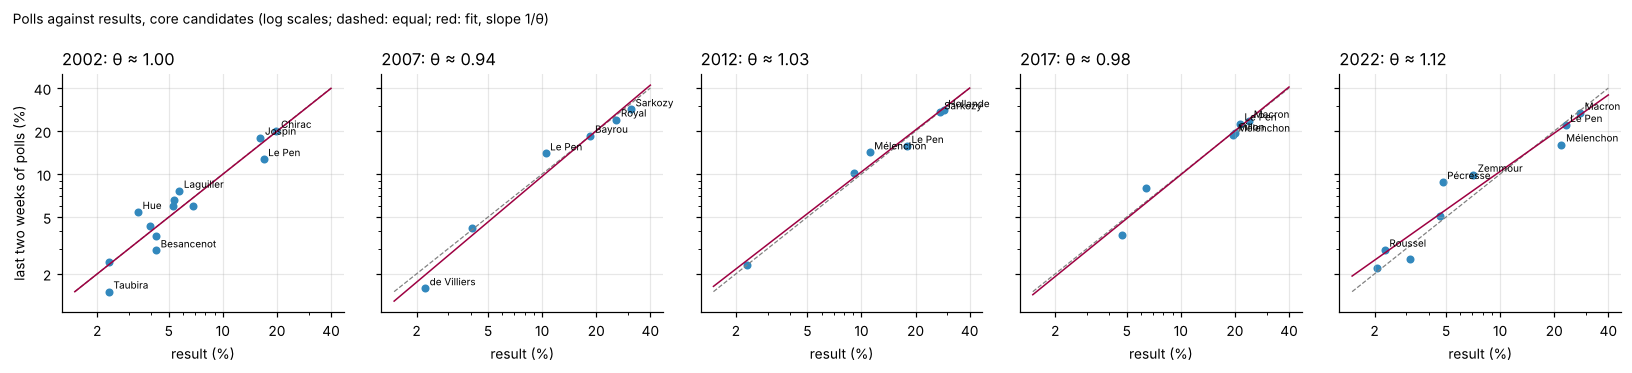

In [4]:
fig, axes = plt.subplots(1, len(ELECTIONS), figsize=(15, 3.4), sharex=True, sharey=True)
for ax, e in zip(axes, ELECTIONS):
    d = lp[lp["election"] == e]
    ax.scatter(d["result"], d["polled"], s=18, color="#3288bd")
    for r in d.itertuples():
        if r.result >= 10 or abs(np.log(r.polled / r.result)) > 0.25:
            ax.annotate(r.slot.split(" ", 1)[1], (r.result, r.polled), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
    lim = np.array([1.5, 40])
    ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
    ax.plot(lim, np.exp(np.polyval(np.polyfit(np.log(d["result"]), np.log(d["polled"]), 1), np.log(lim))), color="#9e0142", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(plt.FixedLocator([2, 5, 10, 20, 40]))
        axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{e}: θ ≈ {theta.loc[e, 'theta_A']:.2f}", loc="left")
    ax.set_xlabel("result (%)")
axes[0].set_ylabel("last two weeks of polls (%)")
fig.suptitle("Polls against results, core candidates (log scales; dashed: equal; red: fit, slope 1/θ)", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "parameters_theta.png")

## 3 · Prior spread ρ<sub>π</sub>

Each voter's prior is π<sub>a</sub> ~ Dirichlet(ρ<sub>π</sub> · s<sup>0</sup>), around the opening poll s<sup>0</sup>, so
ρ<sub>π</sub> = *n*<sub>eff</sub> − 1 with *n*<sub>eff</sub> = mean *p*(100 − *p*) / mean squared deviation from the
opening mean (core candidates, ≥ 2% in the result). The **opening** is the first 45 days of ballot polls within the last
250 days. Two readings of how much the information available then disagreed:

- **all polls**: each poll of the opening around the opening mean (sampling, pollsters, movement);
- **between pollsters**: each pollster's mean over the opening, around the overall mean (pollsters with 2 polls or more).

Voters' beliefs are surely more spread out than the polls they could read, so these are **upper bounds** on
ρ<sub>π</sub>: the least heterogeneity compatible with the information available.

In [5]:
fam = rows.drop_duplicates("poll_id").set_index("poll_id")["institute_family"]
out = []
for e in ELECTIONS:
    d = slot_vals[(slot_vals["election"] == e) & (slot_vals["days_before"] <= 250)]
    d0 = d["days_before"].max()
    op = d[d["days_before"] >= d0 - 45].merge(core[core["election"] == e][["slot"]])
    mean = op.groupby("slot")["value"].mean()
    dev = op["value"] - op["slot"].map(mean)
    pq = op["slot"].map(mean) * (100 - op["slot"].map(mean))
    n_all = pq.mean() / (dev ** 2).mean()
    op = op.assign(firm=op["poll_id"].map(fam))
    firms = op.groupby("firm")["poll_id"].nunique().loc[lambda x: x >= 2].index
    fm = op[op["firm"].isin(firms)].groupby(["firm", "slot"])["value"].mean().reset_index()
    fdev = fm["value"] - fm["slot"].map(mean)
    fpq = fm["slot"].map(mean) * (100 - fm["slot"].map(mean))
    n_between = fpq.mean() / (fdev ** 2).mean() if len(firms) >= 2 else np.nan
    out.append(dict(election=e, opening_from=int(d0), opening_to=int(d0 - 45), polls=op["poll_id"].nunique(),
                    pollsters=len(firms), rho_pi_all_polls=n_all - 1, rho_pi_between_pollsters=n_between - 1))
rho_pi = pd.DataFrame(out).set_index("election")
rho_pi.round(0).to_csv(TABLES / "parameters_rho_pi.csv")
print(f"Current bounds for ρ_π: {BOUNDS['rho_pi']}")
rho_pi.round(0)

Current bounds for ρ_π: (5.0, 200.0)


,opening_from,opening_to,polls,pollsters,rho_pi_all_polls,rho_pi_between_pollsters
election,,,,,,
2002,71,26,26,5,740.0,1372.0
2007,199,154,8,3,290.0,351.0
2012,232,187,2,0,1408.0,NaN
2017,230,185,6,1,344.0,NaN
2022,220,175,14,4,359.0,903.0


## 4 · Tolerance: where a candidate's voters go when the candidate is not offered

**Paired scenarios.** Two hypotheses of the same poll whose tested candidates differ by exactly one candidate X: same
respondents, same day, same pollster; only the offer differs. For each candidate *j* tested in both, its **transfer**
is (share without X − share with X) / share of X: the fraction of X's voters who go to *j*. Shares rescaled to 100 in
each scenario. Net flows only (not individual voters), and stated choices in a hypothetical.

**Distance.** How far the transfers land along the left-right order (Wikipedia's poll-table columns), in **places**
among the candidates of the scenario (adjacent = 1). In the synthetic mode candidates are evenly spaced and tolerance
τ̂ is in zone lengths, so a distance in places reads directly as τ̂ (current bounds: τ̂ ∈ [0.5, 3]). For 2022, also in
the ABM's measured positions (`data/party_positions_2022.csv`), in zone lengths (2/K on [−1, 1], K = 12).

Receivers are grouped by **slot** (the final candidacy they stand for), so that Juppé and Fillon both count as the LR
candidate and each pair's transfers add up to about 100%; candidates with no slot keep their name. Only removals of a
candidate polling **3% or more** are used for the headline numbers: below that, dividing by a tiny share turns noise
into absurd fractions. Only the gains locate where voters go; losses (a candidate losing share as X leaves: noise, or a
change in who answers) are reported separately.

In [6]:
t = rows[rows["share_status"] != "not_tested"].copy()
t["value"] = np.where(t["share_status"] == "value", t["share"], t["share_upper_bound"] * 0.5)
t["value"] = 100 * t["value"] / t.groupby("scenario_id")["value"].transform("sum")
sets = t.groupby("scenario_id").agg(poll=("poll_id", "first"), election=("election", "first"),
                                    days_before=("days_before", "first"), cands=("candidate", frozenset))
lr = ideology.order(ROOT, {int(p.name[:4]): p for p in (ROOT / "data" / "raw" / "wikipedia").glob("*.json")},
                    pd.read_csv(ROOT / "data" / "interim" / "polls_wikipedia.csv", low_memory=False))
lr_pos = lr.set_index(["election", "candidate"])["position"]

# ABM positions (2022), through each candidate's slot and the slot's ballot party
abm = pd.read_csv(ROOT.parent / "strategic-voting-abm-2RS" / "data" / "party_positions_2022.csv", decimal=",") \
    if (ROOT.parent / "strategic-voting-abm-2RS").exists() else None
slot_of = rows.dropna(subset=["slot"]).drop_duplicates(["election", "candidate"]).set_index(["election", "candidate"])["slot"]
party_of_slot = results.set_index(["election", "candidate"])["party"]
abm_pos = abm.set_index("party")["left_right_position"].astype(float) if abm is not None else pd.Series(dtype=float)
def abm_position(e, c):
    if e != 2022:
        return np.nan
    s = slot_of.get((e, c))
    return abm_pos.get(party_of_slot.get((e, s)), np.nan) if s else np.nan

transfers = []
for pid, g in sets.groupby("poll"):
    g = g.reset_index()
    for i in range(len(g)):
        for j in range(len(g)):
            a, b_ = g.loc[i, "cands"], g.loc[j, "cands"]
            if i == j or not (b_ < a and len(a - b_) == 1):
                continue
            e, x = int(g.loc[i, "election"]), next(iter(a - b_))
            w = t[t["scenario_id"] == g.loc[i, "scenario_id"]].set_index("candidate")["value"]
            wo = t[t["scenario_id"] == g.loc[j, "scenario_id"]].set_index("candidate")["value"]
            order = sorted(a, key=lambda c: lr_pos.get((e, c), 0.5))
            for c in b_:
                transfers.append(dict(election=e, poll_id=pid, pair=g.loc[i, "scenario_id"] + "|" + g.loc[j, "scenario_id"],
                                      days_before=g.loc[i, "days_before"], removed=x,
                                      share_removed=w[x], receiver=slot_of.get((e, c)) or c, receiver_name=c,
                                      gain=wo[c] - w[c],
                                      transfer=(wo[c] - w[c]) / w[x],
                                      places=abs(order.index(c) - order.index(x)),
                                      side="left" if order.index(c) < order.index(x) else "right",
                                      zones=abs(abm_position(e, c) - abm_position(e, x)) * 12 / 10))
transfers = pd.DataFrame(transfers)
transfers.round(4).to_csv(TABLES / "parameters_transfers.csv", index=False)
print(f"{transfers[['poll_id', 'removed']].drop_duplicates().shape[0]} (poll, removed candidate) cases in {transfers['poll_id'].nunique()} polls; "
      f"{transfers[transfers['share_removed'] >= 3][['poll_id', 'removed']].drop_duplicates().shape[0]} with the removed candidate at 3% or more")

67 (poll, removed candidate) cases in 55 polls; 63 with the removed candidate at 3% or more


In [7]:
usable = transfers[transfers["share_removed"] >= 3]
n_pairs = usable.groupby(["election", "removed"])["pair"].nunique()
n_polls = usable.groupby(["election", "removed"])["poll_id"].nunique()
per = (usable.groupby(["election", "removed", "receiver"])
       .agg(transfer=("transfer", "sum"), places=("places", "median"), side=("side", "first")).reset_index())
# average over the pairs of each removed candidate (a receiver absent from a pair counts as 0 there)
per["transfer"] = per["transfer"] / [n_pairs[(e, x)] for e, x in zip(per["election"], per["removed"])]
per["polls"] = [n_polls[(e, x)] for e, x in zip(per["election"], per["removed"])]
per["pairs"] = [n_pairs[(e, x)] for e, x in zip(per["election"], per["removed"])]
# label: the candidate's name, or "<party> slot" when others stood in for the final candidate
names = usable.groupby(["election", "removed", "receiver"])["receiver_name"].apply(set)
def label(e, x, r):
    n = names[(e, x, r)]
    if n == {r}:
        return r.split(" ", 1)[1] if " " in r else r
    return f"{party_of_slot.get((e, r), r)} slot"
per["label"] = [label(e, x, r) for e, x, r in zip(per["election"], per["removed"], per["receiver"])]
summary = []
for (e, x), d in per.groupby(["election", "removed"]):
    pos = d[d["transfer"] > 0]
    top = pos.sort_values("transfer", ascending=False).head(3)
    gains = pos["transfer"].sum()
    by_dist = pos.groupby("places")["transfer"].sum().sort_index().cumsum() / gains
    reach = lambda q: int(by_dist[by_dist >= q].index.min())
    summary.append(dict(election=e, removed=x, polls=int(d["polls"].max()), pairs=int(d["pairs"].max()),
                        total=d["transfer"].sum(),
                        top_receivers="; ".join(f"{r.label} {r.transfer:.0%}" for r in top.itertuples()),
                        to_adjacent=by_dist.get(1, 0.0), places_50=reach(0.5), places_80=reach(0.8),
                        mean_places=(pos["places"] * pos["transfer"]).sum() / gains,
                        to_the_left=pos[pos["side"] == "left"]["transfer"].sum() / gains,
                        losses=-d[d["transfer"] < 0]["transfer"].sum()))
summary = pd.DataFrame(summary).sort_values("polls", ascending=False)
summary.round(2).to_csv(TABLES / "parameters_tolerance_by_candidate.csv", index=False)
pd.set_option("display.max_colwidth", 70)
summary.round(2)

,election,removed,polls,pairs,total,top_receivers,to_adjacent,places_50,places_80,mean_places,to_the_left,losses
3,2017,François Bayrou,19,28,1.0,LR slot 28%; Macron 22%; PS slot 17%,0.51,1,3,1.89,0.57,-0.00
12,2022,Éric Zemmour,16,34,1.0,Le Pen 52%; LR slot 16%; Dupont-Aignan 15%,0.52,1,4,2.36,1.00,0.00
2,2017,Emmanuel Macron,9,15,1.0,LR slot 37%; PS slot 21%; Le Pen 14%,0.67,1,3,1.75,0.35,0.00
7,2022,Christiane Taubira,6,6,1.0,Jadot 26%; Macron 22%; PS slot 18%,0.42,2,5,2.62,0.41,0.04
0,2017,Arnaud Montebourg,3,4,1.0,Mélenchon 34%; LR slot 21%; Macron 17%,0.13,2,2,2.32,0.43,-0.00
11,2022,Yannick Jadot,2,2,1.0,Hidalgo 61%; Macron 35%; LR slot 10%,0.85,1,1,1.37,0.57,0.13
5,2022,Anne Hidalgo,2,3,1.0,Jadot 59%; Macron 19%; LR slot 9%,0.61,1,2,1.89,0.05,-0.00
4,2017,Jean-Luc Mélenchon,1,1,1.0,PS slot 33%; Bayrou 21%; Le Pen 17%,0.50,1,3,2.04,0.25,-0.00
1,2017,Cécile Duflot,1,1,1.0,PS slot 33%; Bayrou 33%; Dupont-Aignan 33%,0.33,2,4,2.33,0.00,-0.00
8,2022,François Hollande,1,1,1.0,Jadot 133%; Dupont-Aignan 17%; LR slot 8%,0.05,3,3,2.79,0.84,0.58


In [8]:
main = summary[summary["polls"] >= 3]
print("Candidates removed in 3 polls or more:")
print(f"  share of gains to adjacent candidates: median {main['to_adjacent'].median():.0%}, "
      f"range {main['to_adjacent'].min():.0%}-{main['to_adjacent'].max():.0%}")
print(f"  places within which 80% of the gains land: {sorted(main['places_80'].tolist())}")
print(f"  gain-weighted mean distance: {main['mean_places'].round(2).tolist()} places")
z = usable.dropna(subset=["zones"]).query("transfer > 0")
if len(z):
    zz = z.groupby("removed").apply(lambda d: (d["zones"] * d["transfer"]).sum() / d["transfer"].sum(), include_groups=False)
    print()
    print("2022, ABM positions: gain-weighted mean distance in zone lengths:")
    print(zz.round(2).to_string())

Candidates removed in 3 polls or more:
  share of gains to adjacent candidates: median 51%, range 13%-67%
  places within which 80% of the gains land: [2, 3, 3, 4, 5]
  gain-weighted mean distance: [1.89, 2.36, 1.75, 2.62, 2.32] places

2022, ABM positions: gain-weighted mean distance in zone lengths:
removed
Anne Hidalgo         2.11
Arnaud Montebourg    1.26
François Hollande    1.07
Valérie Pécresse     0.59
Xavier Bertrand      0.82
Yannick Jadot        1.94
Éric Zemmour         1.76


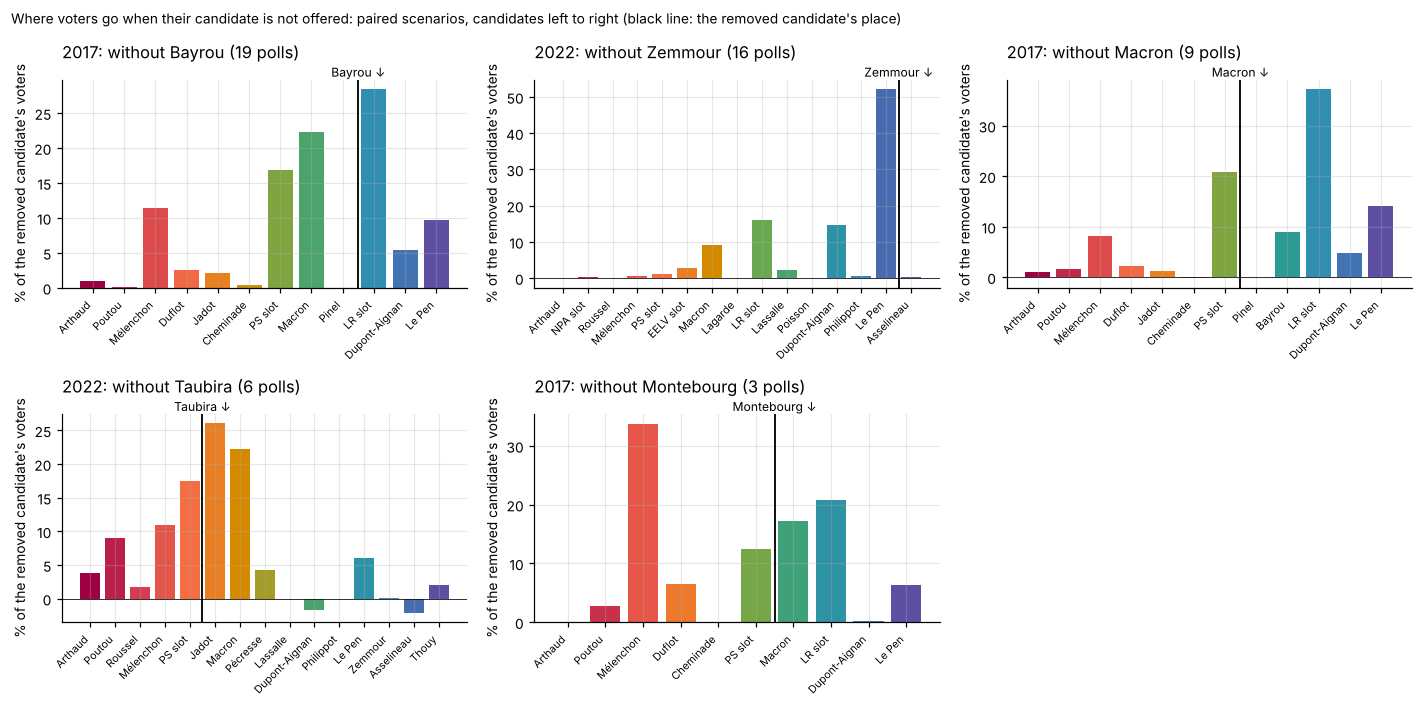

In [9]:
shown = main.head(6)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, r in zip(axes.flat, shown.itertuples()):
    d = per[(per["election"] == r.election) & (per["removed"] == r.removed)].copy()
    d["pos"] = [lr_pos.get((r.election, c), 0.5) for c in d["receiver"]]
    d = d.sort_values("pos")
    xpos = lr_pos.get((r.election, r.removed), 0.5)
    col = ideology.colours(d["receiver"].tolist())
    ax.bar(range(len(d)), d["transfer"] * 100, color=[col[c] for c in d["receiver"]])
    k = int(np.searchsorted(d["pos"].to_numpy(), xpos))
    ax.axvline(k - 0.5, color="black", lw=1.2)
    ax.text(k - 0.5, 1.0, f"{r.removed.split(' ', 1)[1]} ↓", ha="center", va="bottom", fontsize=8,
            transform=ax.get_xaxis_transform())
    ax.set_xticks(range(len(d)), d["label"], rotation=45, ha="right", fontsize=7)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{r.election}: without {r.removed.split(' ', 1)[1]} ({r.polls} polls)", loc="left", pad=14)
    ax.set_ylabel("% of the removed candidate's voters")
for ax in axes.flat[len(shown):]:
    ax.remove()
fig.suptitle("Where voters go when their candidate is not offered: paired scenarios, candidates left to right "
             "(black line: the removed candidate's place)", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "parameters_transfers.png")

## 5 · Real-world ranges for the synthetic setup

What real polls and results look like, to set against the synthetic electorates and polls later (nothing is run here).
Every ballot poll of the last 250 days, with all the candidates it tests; shares rescaled to 100. **Rank slope**: the
slope of log share against log rank (candidates at 0% left out) (more negative: support falls faster from the leader down). The synthetic sweeps
use K = 6, 8 and 9 candidates.

In [10]:
def describe_poll(sh):
    st = metrics.structure(sh)
    s = np.sort(sh.to_numpy(float))[::-1]
    return dict(n_candidates=len(s), n_at_5=int((s >= 5).sum()), enp=st["enp"], hhi=st["hhi"],
                leader_share=s[0], gap_12=st["gap_12"], gap_23=st["gap_23"], cliff=st["cliff"],
                cliff_location=st["cliff_location"], cliff_ratio=st["cliff_ratio"],
                rank_slope=np.polyfit(np.log(np.arange(1, (s > 0).sum() + 1)), np.log(s[s > 0]), 1)[0])

pp = []
for (e, pid), g in b[b["days_before"] <= 250].groupby(["election", "poll_id"]):
    sh = metrics.shares_of(g)
    pp.append(dict(election=e, poll_id=pid, phase=g["phase"].iloc[0], **describe_poll(100 * sh / sh.sum())))
pp = pd.DataFrame(pp)
rr = pd.DataFrame([dict(election=e, **describe_poll(results[results["election"] == e].set_index("candidate")["share"]))
                   for e in ELECTIONS]).set_index("election")
METRICS = ["n_candidates", "n_at_5", "enp", "hhi", "leader_share", "gap_12", "gap_23", "cliff", "cliff_location",
           "cliff_ratio", "rank_slope"]
q = lambda x: pd.Series({"p10": x.quantile(0.1), "median": x.median(), "p90": x.quantile(0.9)})
ranges = pd.concat({m: pd.concat({"all polls": q(pp[m]), **{str(e): q(pp[pp["election"] == e][m]) for e in ELECTIONS}}, axis=1)
                    for m in METRICS})
ranges.round(3).to_csv(TABLES / "parameters_real_ranges.csv")
rr.round(3).to_csv(TABLES / "parameters_real_ranges_results.csv")
print(f"{len(pp)} ballot polls in the last 250 days")
ranges.xs("median", level=1).round(2)

541 ballot polls in the last 250 days


,all polls,2002,2007,2012,2017,2022
n_candidates,12.00,16.00,11.00,10.00,11.00,13.00
n_at_5,5.00,7.00,4.00,5.00,5.00,6.00
enp,5.32,7.51,4.68,4.69,5.24,6.49
hhi,0.19,0.13,0.21,0.21,0.19,0.15
leader_share,27.00,23.00,30.89,29.55,25.94,26.00
gap_12,4.06,2.00,4.05,3.17,1.00,7.94
gap_23,6.00,9.95,8.02,9.98,5.00,3.00
cliff,9.48,9.95,11.00,10.28,9.00,8.00
cliff_location,2.00,2.00,2.00,2.00,4.00,1.00
cliff_ratio,0.84,0.91,0.85,0.81,0.80,0.85


In [11]:
print("All polls, 10th to 90th percentile, and the five results:")
summary = pd.DataFrame({"p10": ranges.xs("p10", level=1)["all polls"], "median": ranges.xs("median", level=1)["all polls"],
                        "p90": ranges.xs("p90", level=1)["all polls"]}).join(rr[METRICS].T)
summary.round(2)

All polls, 10th to 90th percentile, and the five results:


,p10,median,p90,2002,2007,2012,2017,2022
n_candidates,9.00,12.00,16.00,16.00,12.00,10.00,11.00,12.00
n_at_5,4.00,5.00,7.00,7.00,4.00,5.00,5.00,4.00
enp,4.55,5.32,7.03,8.66,4.70,4.77,5.32,5.23
hhi,0.14,0.19,0.22,0.12,0.21,0.21,0.19,0.19
leader_share,23.00,27.00,32.16,19.88,31.18,28.63,24.01,27.85
gap_12,1.00,4.06,9.50,3.02,5.31,1.45,2.71,4.70
gap_23,1.00,6.00,12.12,0.68,7.30,9.28,1.29,1.20
cliff,6.97,9.48,13.00,9.34,8.13,9.28,13.22,14.88
cliff_location,1.00,2.00,4.00,3.00,3.00,2.00,4.00,3.00
cliff_ratio,0.77,0.84,0.90,0.93,0.78,0.80,0.92,0.92


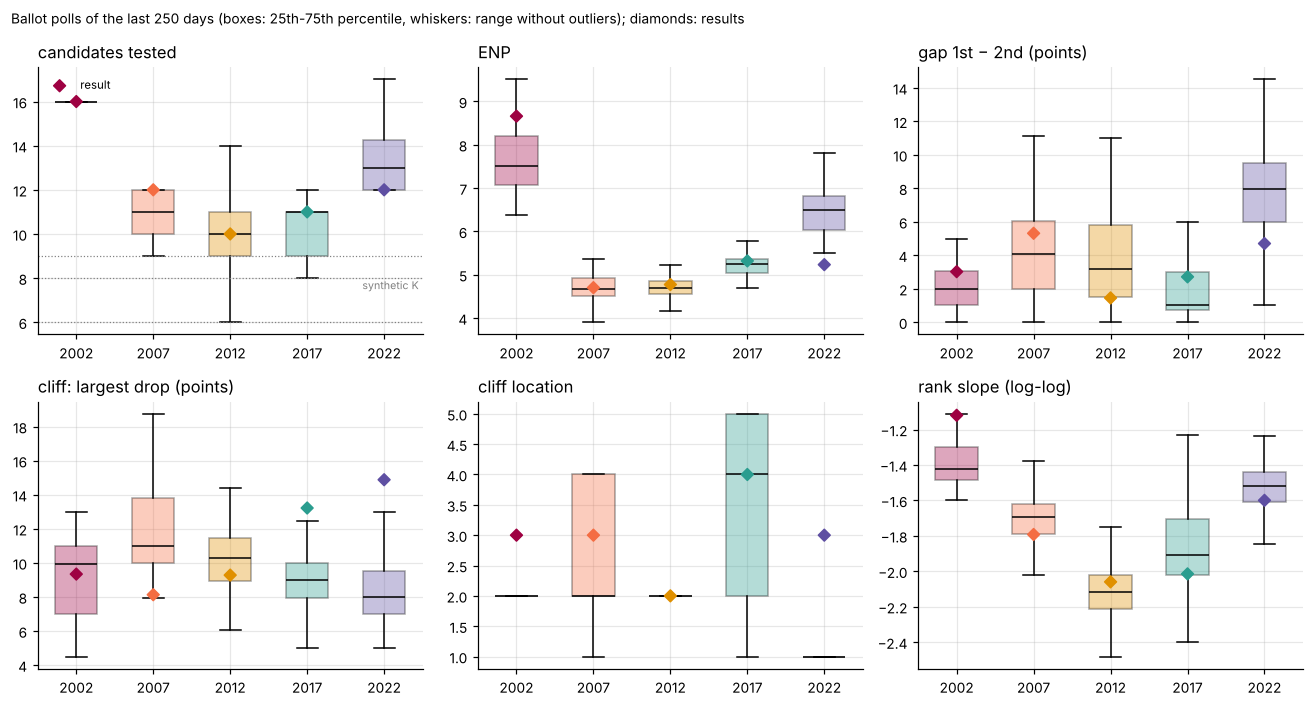

In [12]:
show = {"n_candidates": "candidates tested", "enp": "ENP", "gap_12": "gap 1st − 2nd (points)",
        "cliff": "cliff: largest drop (points)", "cliff_location": "cliff location", "rank_slope": "rank slope (log-log)"}
E_COLOURS = dict(zip(ELECTIONS, ["#9e0142", "#f46d43", "#e09000", "#2a9d8f", "#5e4fa2"]))
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (m, label) in zip(axes.flat, show.items()):
    data = [pp[pp["election"] == e][m] for e in ELECTIONS]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False)
    for patch, e in zip(bp["boxes"], ELECTIONS):
        patch.set_facecolor(E_COLOURS[e]); patch.set_alpha(0.35)
    for med in bp["medians"]:
        med.set_color("black")
    ax.scatter(range(1, len(ELECTIONS) + 1), rr.loc[ELECTIONS, m], color=[E_COLOURS[e] for e in ELECTIONS],
               zorder=3, s=30, marker="D", label="result")
    if m == "n_candidates":
        for k in (6, 8, 9):
            ax.axhline(k, color="grey", lw=0.8, ls=":")
        ax.text(5.45, 7.5, "synthetic K", fontsize=7, color="grey", ha="right")
    ax.set_xticks(range(1, len(ELECTIONS) + 1), ELECTIONS)
    ax.set_title(label, loc="left")
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.suptitle("Ballot polls of the last 250 days (boxes: 25th-75th percentile, whiskers: range without outliers); "
             "diamonds: results", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "parameters_real_ranges.png")